# Análisis exploratorio del catálogo sísmico de Lima

## Objetivo
Explorar los registros sísmicos del catálogo IGP antes de
entrenar un modelo Neural Point Process basado en LSTM.

Se analizarán:
- Cantidad y calidad de registros.
- Distribución de magnitudes.
- Frecuencia anual de eventos.
- Diferencias entre entrenamiento y prueba.

El EDA no modifica el catálogo original.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Ubicar el CSV desde la raíz o desde notebooks/
ruta = Path("data/raw/SISMOS_LIMA_FORMATO_MODELO_cat.csv")

if not ruta.exists():
    ruta = Path("../data/raw/SISMOS_LIMA_FORMATO_MODELO_cat.csv")

df = pd.read_csv(ruta)

# Construir una fecha utilizando las columnas originales
df["fecha"] = pd.to_datetime(
    df[["year", "month", "day", "hour", "minute", "second"]]
)

print("Total de registros:", len(df))
print("Primera fecha:", df["fecha"].min())
print("Última fecha:", df["fecha"].max())

display(df.head())

Total de registros: 2578
Primera fecha: 1961-01-28 03:24:46
Última fecha: 2026-11-02 15:28:08


,Unnamed: 0,year,month,day,hour,minute,second,mw,fecha
0,0,1961,1,28,3,24,46.0,6.0,1961-01-28 03:24:46
1,1,1962,9,28,22,14,52.0,4.8,1962-09-28 22:14:52
2,2,1963,4,28,5,22,5.0,5.3,1963-04-28 05:22:05
3,3,1963,6,27,13,15,15.0,4.7,1963-06-27 13:15:15
4,4,1963,7,5,5,48,13.0,6.0,1963-07-05 05:48:13


In [4]:
print("Valores nulos por columna:")
display(df.isnull().sum())

print("Registros repetidos por fecha y magnitud:")
print(df.duplicated(subset=["fecha", "mw"]).sum())

print("\nEstadísticas de magnitud:")
display(df["mw"].describe())

Valores nulos por columna:


Unnamed: 0    0
year          0
month         0
day           0
hour          0
minute        0
second        0
mw            0
fecha         0
dtype: int64

Registros repetidos por fecha y magnitud:
0

Estadísticas de magnitud:


count    2578.000000
mean        4.590768
std         0.521341
min         3.200000
25%         4.500000
50%         4.600000
75%         4.900000
max         8.000000
Name: mw, dtype: float64

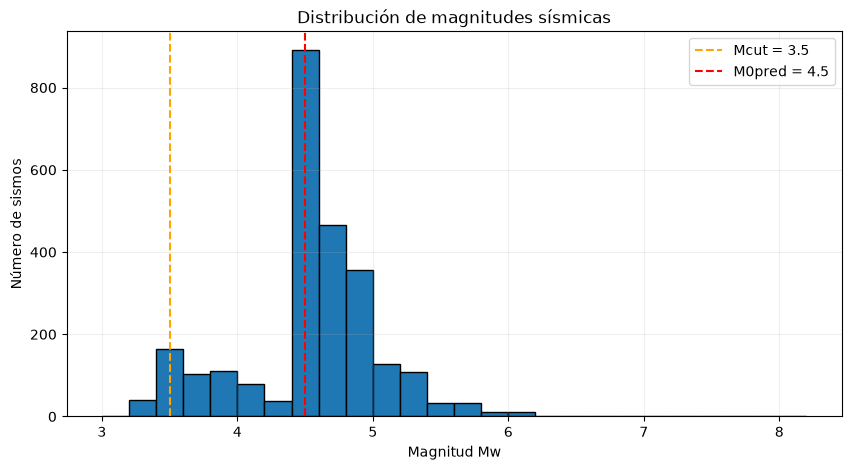

Registros originales: 2578
Registros Mw > 3.5: 2441
Registros Mw >= 4.5: 2046


In [5]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["mw"],
    bins=np.arange(3.0, 8.3, 0.2),
    edgecolor="black"
)

plt.axvline(3.5, color="orange", linestyle="--",
            label="Mcut = 3.5")

plt.axvline(4.5, color="red", linestyle="--",
            label="M0pred = 4.5")

plt.title("Distribución de magnitudes sísmicas")
plt.xlabel("Magnitud Mw")
plt.ylabel("Número de sismos")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Registros originales:", len(df))
print("Registros Mw > 3.5:", (df["mw"] > 3.5).sum())
print("Registros Mw >= 4.5:", (df["mw"] >= 4.5).sum())

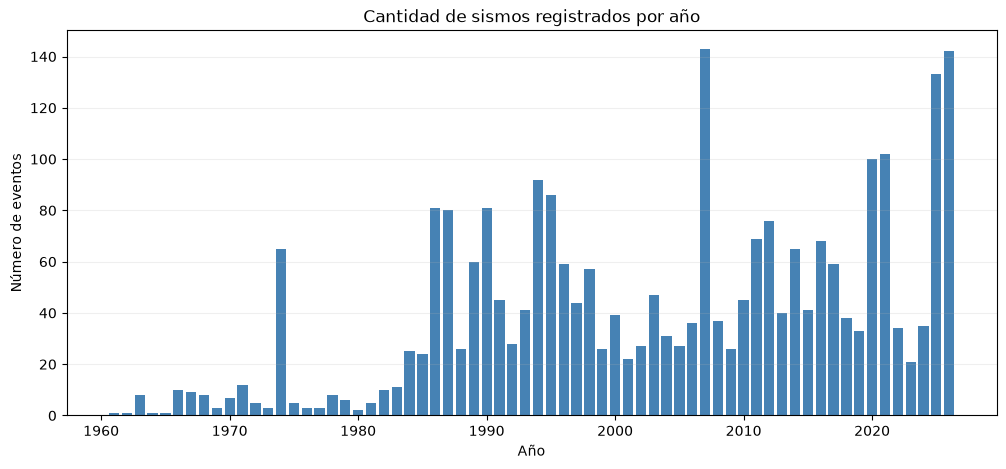

In [6]:
eventos_anuales = df.groupby(df["fecha"].dt.year).size()

plt.figure(figsize=(12, 5))

plt.bar(
    eventos_anuales.index,
    eventos_anuales.values,
    color="steelblue"
)

plt.title("Cantidad de sismos registrados por año")
plt.xlabel("Año")
plt.ylabel("Número de eventos")
plt.grid(axis="y", alpha=0.2)
plt.show()

In [7]:
# Mantener el filtro original del proyecto
df_filtrado = df[df["mw"] > 3.5].copy()

# Corte cronológico usado en el experimento original
fecha_corte = df["fecha"].min() + pd.Timedelta(hours=450000)

train = df_filtrado[df_filtrado["fecha"] < fecha_corte]
test = df_filtrado[df_filtrado["fecha"] >= fecha_corte]

print("Fecha de corte:", fecha_corte)
print("Registros de entrenamiento:", len(train))
print("Registros de prueba:", len(test))

resumen = pd.DataFrame({
    "Periodo": ["Entrenamiento", "Prueba"],
    "Total": [len(train), len(test)],
    "Mw >= 4.5": [
        (train["mw"] >= 4.5).sum(),
        (test["mw"] >= 4.5).sum()
    ]
})

resumen["Porcentaje Mw >= 4.5"] = (
    resumen["Mw >= 4.5"] / resumen["Total"] * 100
).round(2)

display(resumen)

Fecha de corte: 2012-05-30 03:24:46
Registros de entrenamiento: 1621
Registros de prueba: 820


,Periodo,Total,Mw >= 4.5,Porcentaje Mw >= 4.5
0,Entrenamiento,1621,1612,99.44
1,Prueba,820,434,52.93
